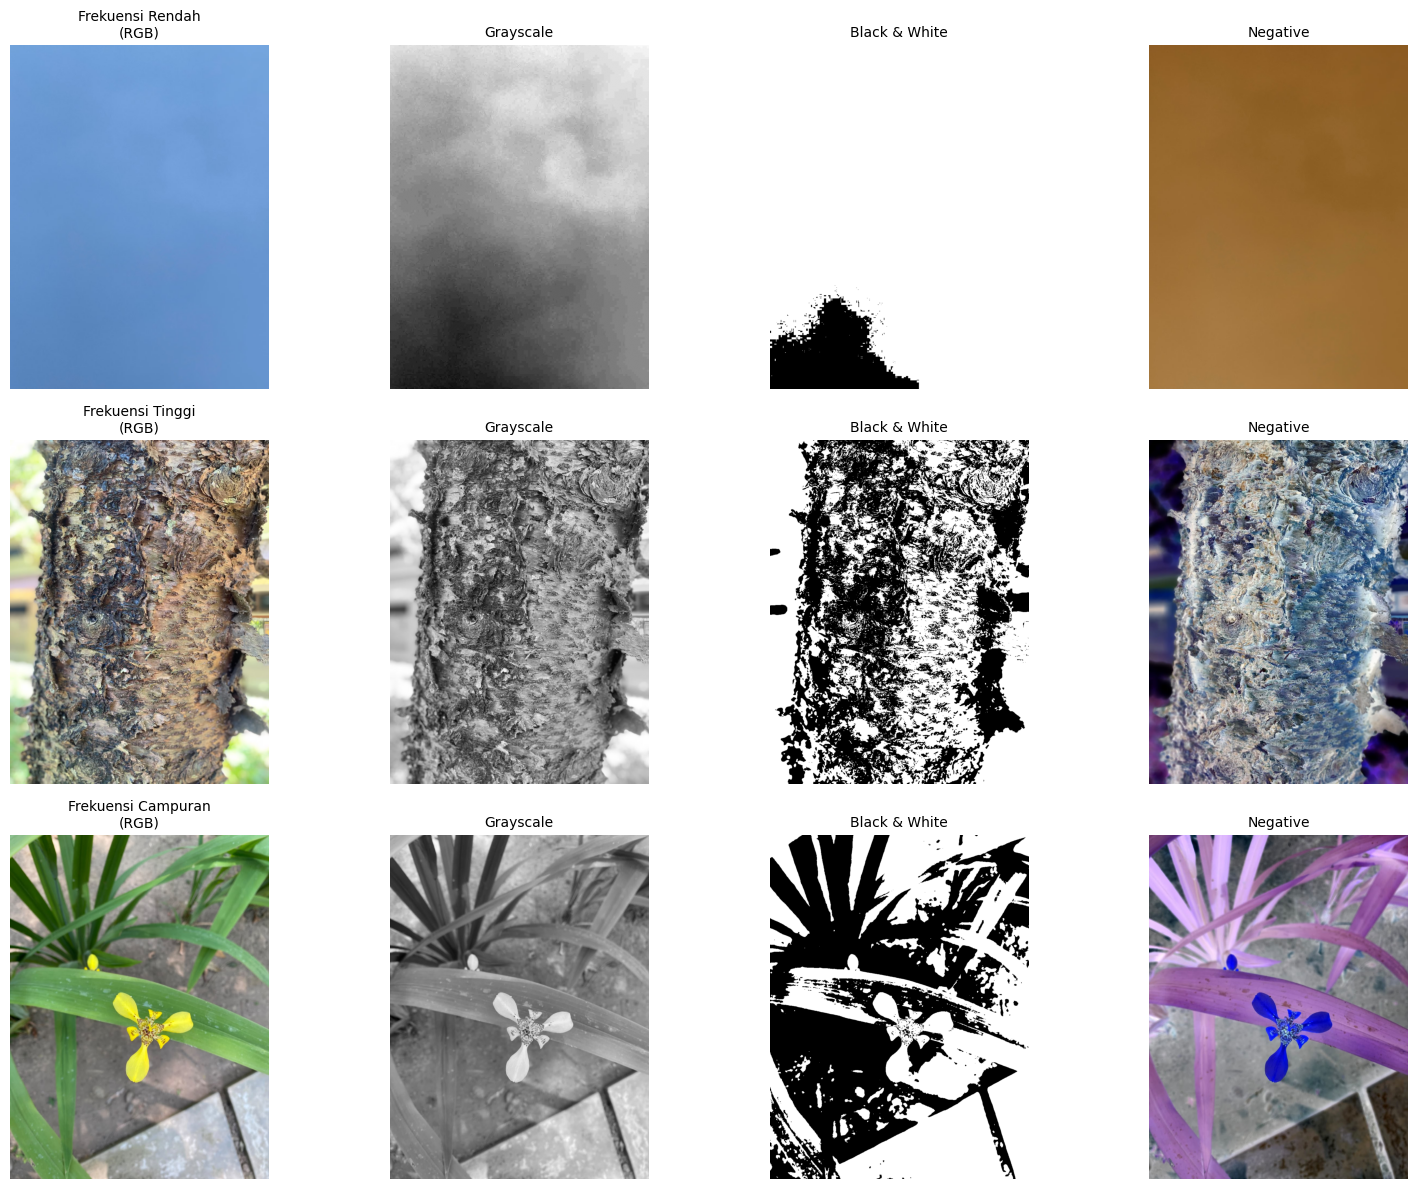

In [15]:
import cv2
import matplotlib.pyplot as plt

# 1. Simpan daftar nama file dataset kamu ke dalam daftar (list)
files = ['freqrendah.jpeg', 'freqtinggi.jpeg', 'freqcampuran.jpeg']
labels = ['Frekuensi Rendah', 'Frekuensi Tinggi', 'Frekuensi Campuran']

# 2. Siapkan grid subplot: 3 baris (untuk 3 citra) x 4 kolom (RGB, Gray, BW, Negative)
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 12))

# 3. Looping untuk memproses setiap gambar
for i, filename in enumerate(files):
    # a. Baca citra
    image_bgr = cv2.imread(filename)

    # Keamanan: Cek apakah file berhasil dibaca
    if image_bgr is None:
        print(f"File {filename} tidak ditemukan, periksa kembali nama file!")
        continue

    # b. Konversi BGR ke RGB
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    # c. Operasi 1: RGB to Grayscale
    image_gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

    # d. Operasi 2: RGB to Black & White (Binary)
    _, image_bw = cv2.threshold(image_gray, 128, 255, cv2.THRESH_BINARY)

    # e. Operasi 3: RGB to Negative
    image_negative = 255 - image_rgb

    # f. Tampilkan ke dalam grid matplotlib
    processed_images = [image_rgb, image_gray, image_bw, image_negative]
    titles = [f'{labels[i]}\n(RGB)', 'Grayscale', 'Black & White', 'Negative']

    for j in range(4):
        ax = axes[i, j]

        # Tampilkan dengan colormap gray jika gambar 2D (Grayscale / BW)
        if len(processed_images[j].shape) == 2:
            ax.imshow(processed_images[j], cmap='gray')
        else:
            ax.imshow(processed_images[j])

        ax.set_title(titles[j], fontsize=10)
        ax.axis('off')

plt.savefig('hasil_visualisasi_matriks.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()